In [38]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pickle
import glob

In [39]:
df = pd.DataFrame(columns=['model', 'dataset', 'method', 'iter', 'acc@1'])

paths = glob.glob('./output/*/*/*')
for path in sorted(paths):
    if not os.path.isdir(path):
        continue

    model, dataset, method = path.split('/')[-3:]
    acc1 = []
    acc5 = []

    for iter in os.listdir(path):
        if not os.path.exists(os.path.join(path, iter, 'results.pkl')):
            continue
        
        results = pickle.load(open(os.path.join(path, iter, 'results.pkl'), 'rb'))

        acc1.append(results['accuracy1'])
        acc5.append(results['accuracy5'])
    
                
    if len(acc1) > 0:
        df = df.append({
            'model': model,
            'dataset': dataset,
            'method': method,
            'iter': len(acc1),
            'acc@1': f'{np.mean(acc1):.2f}±{np.std(acc1):.2f}',
        }, ignore_index=True)
print(df)

             model        dataset      method iter       acc@1
0   conv2next-tiny       cifar100    baseline    1  83.69±0.00
1   conv2next-tiny       cifar100          sn    1  81.46±0.00
2   conv2next-tiny       cifar100    snr_0.01    1  83.46±0.00
3   conv2next-tiny       cifar100    snvr_1.0    1  83.49±0.00
4   conv2next-tiny       cifar100         srr    1  82.96±0.00
5   conv2next-tiny       cifar100          tb    1  83.11±0.00
6   conv2next-tiny       cifar100         war    1  83.65±0.00
7   conv2next-tiny       cifar100          wn    1  82.02±0.00
8   conv2next-tiny     cifar100_1    baseline    3  83.33±0.33
9   conv2next-tiny     cifar100_1          sn    2  80.91±0.06
10  conv2next-tiny     cifar100_1  snr_0.0001    3  83.58±0.12
11  conv2next-tiny     cifar100_1   snr_0.001    3  83.63±0.27
12  conv2next-tiny     cifar100_1    snr_0.01    6  83.19±0.27
13  conv2next-tiny     cifar100_1     snr_0.1    4  83.59±0.07
14  conv2next-tiny     cifar100_1   snvr_0.01    3  83.

In [45]:
plt.rc('text', usetex=True)
plt.rc('font', family='Times New Roman')

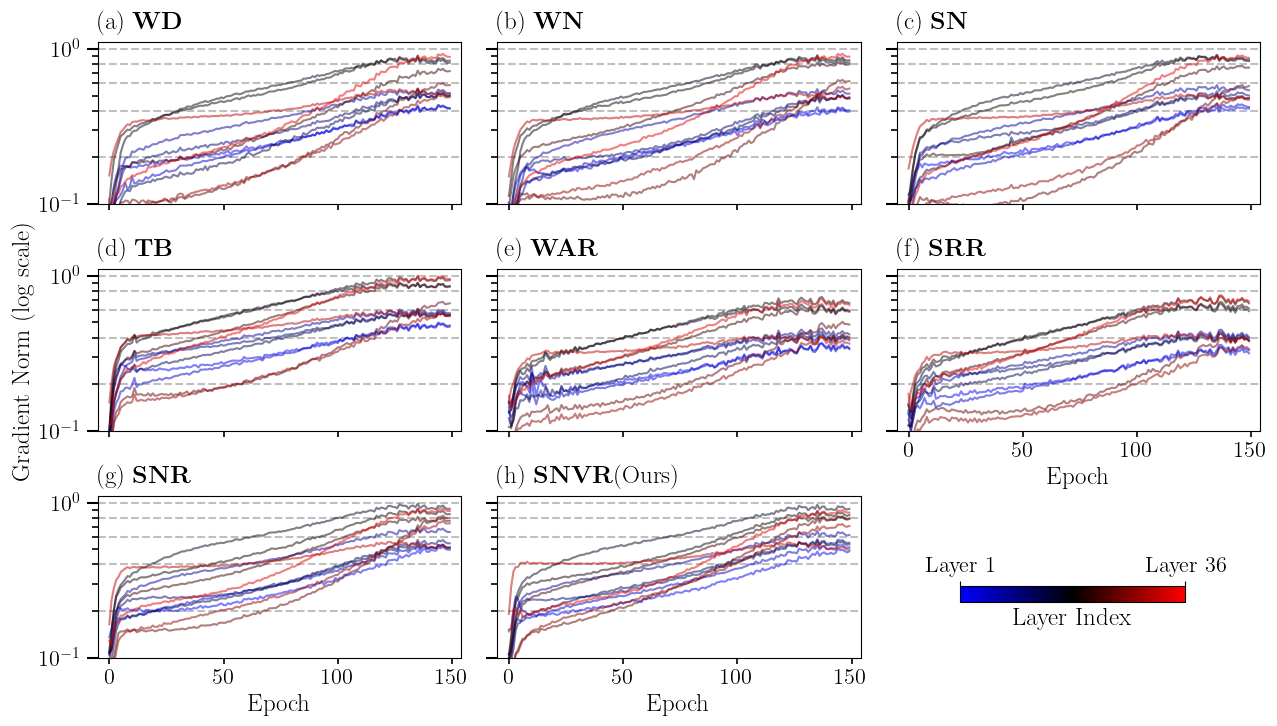

In [46]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from math import ceil

titles = [r'(a) \textbf{WD}', r'(b) \textbf{WN}', r'(c) \textbf{SN}', r'(d) \textbf{TB}', r'(e) \textbf{WAR}', r'(f) \textbf{SRR}', r'(g) \textbf{SNR}', r'(h) \textbf{SNVR}(Ours)']
methods = ['baseline','wn', 'sn','tb', 'war', 'srr', 'snr', 'snvr']

fig, axs = plt.subplots(3, 3, figsize=(15, 8))

cdict = {
    'red':   ((0.0, 0.0, 0.0), 
              (0.5, 0.0, 0.0), 
              (1.0, 1.0, 1.0)),
    'green': ((0.0, 0.0, 0.0), 
              (1.0, 0.0, 0.0)),
    'blue':  ((0.0, 1.0, 1.0), 
              (0.5, 0.0, 0.0), 
              (1.0, 0.0, 0.0)) 
}
blue_black_red_cmap = LinearSegmentedColormap('BlueBlackRed', cdict)


for i, method in enumerate(methods):
    epoch_grad_norms = np.load(f'output/resnet34/cifar100/{method}/0/grad.npy')
    if method == 'wn':
        epoch_grad_norms = epoch_grad_norms[:,::2]
        
    ax = axs.flatten()[i]

    norm_factor = epoch_grad_norms.shape[1]

    for idx in range(1, norm_factor, 3):
        grad_norms = epoch_grad_norms[:,idx]
        x = np.arange(grad_norms.shape[0])
        y = grad_norms.mean(axis=1)
        y = np.where(np.isinf(y), np.nan, y)
        s = pd.Series(y)
        y = s.interpolate()

        c_index = idx / norm_factor
        rgb = blue_black_red_cmap(c_index)

        ax.plot(x, y, alpha=.5, color=rgb)

    ax.set_yscale('log')
    ax.set_ylim(0.1, 1.1)
    ax.set_xlim(-5, x.max()+5)
    
    if i in [5, 6, 7]:
        ax.set_xlabel('Epoch', fontsize=18)
    else:
        ax.set_xticklabels([])

    if i == 3:
        ax.set_ylabel('Gradient Norm (log scale)', fontsize=18)
    
    if i % 3 != 0:
        ax.set_yticklabels([])

    for y in [0.2,.4,.6,.8,1.]:
        ax.axhline(y, linestyle='--', color='gray', alpha=0.5, zorder=-1)


    ax.set_title(titles[i], fontsize=18, loc='left', pad=10)

    ax.tick_params(labelsize=16, which='major', axis='y', size=8, width=1.5)
    ax.tick_params(labelsize=16, which='minor', axis='y', size=4, width=1.2)
    ax.tick_params(labelsize=16, axis='x', size=4, width=1.2)

ax = axs.flatten()[8]
ax.axis('off')

cbar_ax = fig.add_axes([0.70, 0.18, 0.15, 0.02])
cbar = plt.colorbar(plt.cm.ScalarMappable(cmap=blue_black_red_cmap), 
                    cax=cbar_ax, 
                    orientation='horizontal',
                    ticks=[0, 1])
cbar.set_ticklabels(['Layer 1', f'Layer {norm_factor}'], fontsize=16)
cbar_ax.xaxis.tick_top()
cbar.set_label('Layer Index', fontsize=18)
cbar_ax.xaxis.set_label_position('bottom')

plt.subplots_adjust(wspace=0.1, hspace=0.4)
plt.savefig('figures/visualization_grad_norm.pdf', bbox_inches='tight', dpi=300)

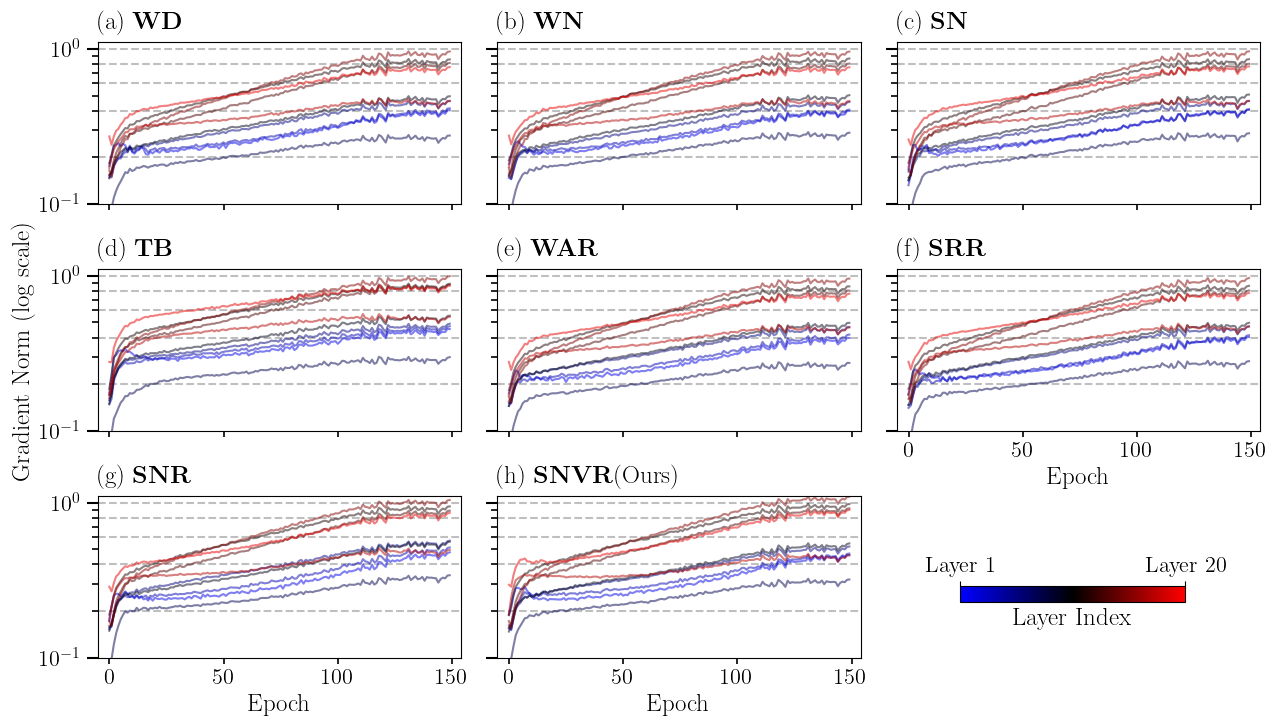

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from math import ceil

titles = [r'(a) \textbf{WD}', r'(b) \textbf{WN}', r'(c) \textbf{SN}', r'(d) \textbf{TB}', r'(e) \textbf{WAR}', r'(f) \textbf{SRR}', r'(g) \textbf{SNR}', r'(h) \textbf{SNVR}(Ours)']
methods = ['baseline','wn', 'sn','tb', 'war', 'srr', 'snr', 'snvr']

fig, axs = plt.subplots(3, 3, figsize=(15, 8))

cdict = {
    'red':   ((0.0, 0.0, 0.0), 
              (0.5, 0.0, 0.0), 
              (1.0, 1.0, 1.0)),
    'green': ((0.0, 0.0, 0.0), 
              (1.0, 0.0, 0.0)),
    'blue':  ((0.0, 1.0, 1.0), 
              (0.5, 0.0, 0.0), 
              (1.0, 0.0, 0.0)) 
}
blue_black_red_cmap = LinearSegmentedColormap('BlueBlackRed', cdict)


for i, method in enumerate(methods):
    epoch_grad_norms = np.load(f'output/resnet18/cifar100/{method}/3/grad.npy')
    if method == 'wn':
        epoch_grad_norms = epoch_grad_norms[:,::2]
        
    ax = axs.flatten()[i]

    norm_factor = epoch_grad_norms.shape[1]

    for idx in range(1, norm_factor, 2):
        grad_norms = epoch_grad_norms[:,idx]
        x = np.arange(grad_norms.shape[0])
        y = grad_norms.mean(axis=1)
        y = np.where(np.isinf(y), np.nan, y)
        s = pd.Series(y)
        y = s.interpolate()

        c_index = idx / norm_factor
        rgb = blue_black_red_cmap(c_index)

        ax.plot(x, y, alpha=.5, color=rgb)

    ax.set_yscale('log')
    ax.set_ylim(0.1, 1.1)
    ax.set_xlim(-5, x.max()+5)
    
    if i in [5, 6, 7]:
        ax.set_xlabel('Epoch', fontsize=18)
    else:
        ax.set_xticklabels([])

    if i == 3:
        ax.set_ylabel('Gradient Norm (log scale)', fontsize=18)
    
    if i % 3 != 0:
        ax.set_yticklabels([])

    for y in [0.2,.4,.6,.8,1.]:
        ax.axhline(y, linestyle='--', color='gray', alpha=0.5, zorder=-1)


    ax.set_title(titles[i], fontsize=18, loc='left', pad=10)

    ax.tick_params(labelsize=16, which='major', axis='y', size=8, width=1.5)
    ax.tick_params(labelsize=16, which='minor', axis='y', size=4, width=1.2)
    ax.tick_params(labelsize=16, axis='x', size=4, width=1.2)

ax = axs.flatten()[8]
ax.axis('off')

cbar_ax = fig.add_axes([0.70, 0.18, 0.15, 0.02])
cbar = plt.colorbar(plt.cm.ScalarMappable(cmap=blue_black_red_cmap), 
                    cax=cbar_ax, 
                    orientation='horizontal',
                    ticks=[0, 1])
cbar.set_ticklabels(['Layer 1', f'Layer {norm_factor}'], fontsize=16)
cbar_ax.xaxis.tick_top()
cbar.set_label('Layer Index', fontsize=18)
cbar_ax.xaxis.set_label_position('bottom')

plt.subplots_adjust(wspace=0.1, hspace=0.4)
plt.savefig('figures/visualization_grad_norm_resnet18.pdf', bbox_inches='tight', dpi=300)

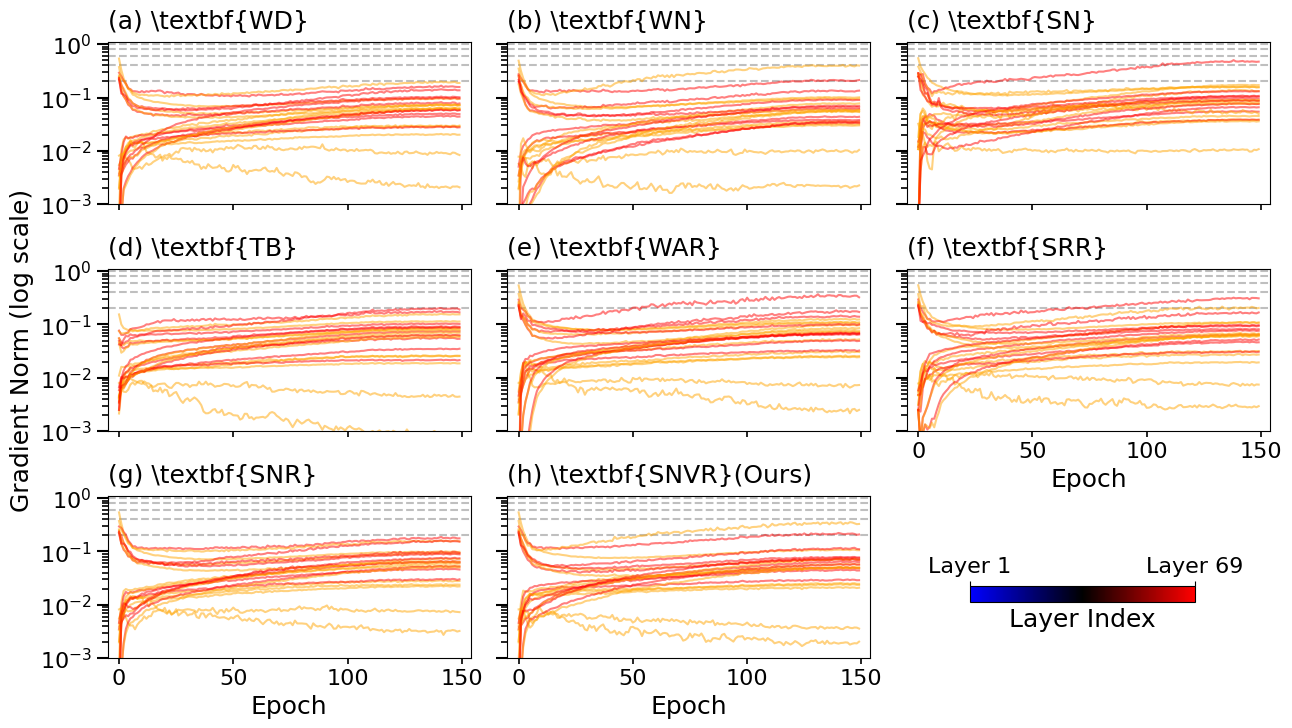

In [41]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap # 추가 import
from math import ceil

import torch

from models.conv2next import conv2next_tiny
import torch.nn as nn

titles = [r'(a) \textbf{WD}', r'(b) \textbf{WN}', r'(c) \textbf{SN}', r'(d) \textbf{TB}', r'(e) \textbf{WAR}', r'(f) \textbf{SRR}', r'(g) \textbf{SNR}', r'(h) \textbf{SNVR}(Ours)']
methods = ['baseline','wn', 'sn','tb', 'war', 'srr', 'snr_0.01', 'snvr_1.0']

model = conv2next_tiny(num_classes=100)

fig, axs = plt.subplots(3, 3, figsize=(15, 8))
modules = [module for module in model.modules() if isinstance(module, nn.Conv2d) or isinstance(module, nn.Linear)]
modules = modules[1:-1]

cdict = {
    'red':   ((0.0, 0.0, 0.0), 
              (0.5, 0.0, 0.0), 
              (1.0, 1.0, 1.0)),
    'green': ((0.0, 0.0, 0.0), 
              (1.0, 0.0, 0.0)),
    'blue':  ((0.0, 1.0, 1.0), 
              (0.5, 0.0, 0.0), 
              (1.0, 0.0, 0.0)) 
}
blue_black_red_cmap = LinearSegmentedColormap('BlueBlackRed', cdict)


for i, method in enumerate(methods):
    epoch_grad_norms = np.load(f'output/conv2next-tiny/cifar100/{method}/0/grad.npy')
    if method == 'wn':
        epoch_grad_norms = epoch_grad_norms[:,::2]
    epoch_grad_norms = epoch_grad_norms[:,1:]
        
    ax = axs.flatten()[i]

    norm_factor = epoch_grad_norms.shape[1]

    for idx, module in enumerate(modules[::3]):
        if isinstance(module, nn.Conv2d):
            c = 'orange'
        else:
            c = 'red'

        grad_norms = epoch_grad_norms[:,idx]
        x = np.arange(grad_norms.shape[0])
        y = grad_norms.mean(axis=1)
        y = np.where(np.isinf(y), np.nan, y)
        s = pd.Series(y)
        y = s.interpolate()

        ax.plot(x, y, alpha=.5, color=c)

    ax.set_yscale('log')
    ax.set_ylim(0.001, 1.1)
    ax.set_xlim(-5, x.max()+5)
    
    if i in [5, 6, 7]:
        ax.set_xlabel('Epoch', fontsize=18)
    else:
        ax.set_xticklabels([])

    if i == 3:
        ax.set_ylabel('Gradient Norm (log scale)', fontsize=18)
    
    if i % 3 != 0:
        ax.set_yticklabels([])

    for y in [0.2,.4,.6,.8,1.]:
        ax.axhline(y, linestyle='--', color='gray', alpha=0.5, zorder=-1)


    ax.set_title(titles[i], fontsize=18, loc='left', pad=10)

    ax.tick_params(labelsize=16, which='major', axis='y', size=8, width=1.5)
    ax.tick_params(labelsize=16, which='minor', axis='y', size=4, width=1.2)
    ax.tick_params(labelsize=16, axis='x', size=4, width=1.2)

ax = axs.flatten()[8]
ax.axis('off')

cbar_ax = fig.add_axes([0.70, 0.18, 0.15, 0.02]) # x, y, width, height (가로로 긴 직사각형)
cbar = plt.colorbar(plt.cm.ScalarMappable(cmap=blue_black_red_cmap), 
                    cax=cbar_ax, 
                    orientation='horizontal',
                    ticks=[0, 1])
cbar.set_ticklabels(['Layer 1', f'Layer {norm_factor}'], fontsize=16)
cbar_ax.xaxis.tick_top()
cbar.set_label('Layer Index', fontsize=18)
cbar_ax.xaxis.set_label_position('bottom')

plt.subplots_adjust(wspace=0.1, hspace=0.4)
plt.savefig('figures/visualization_grad_norm.pdf', bbox_inches='tight', dpi=300)

=== baseline ===
=== wn ===
=== sn ===
=== tb ===
=== war ===
=== srr ===
=== snr ===
=== snvr ===


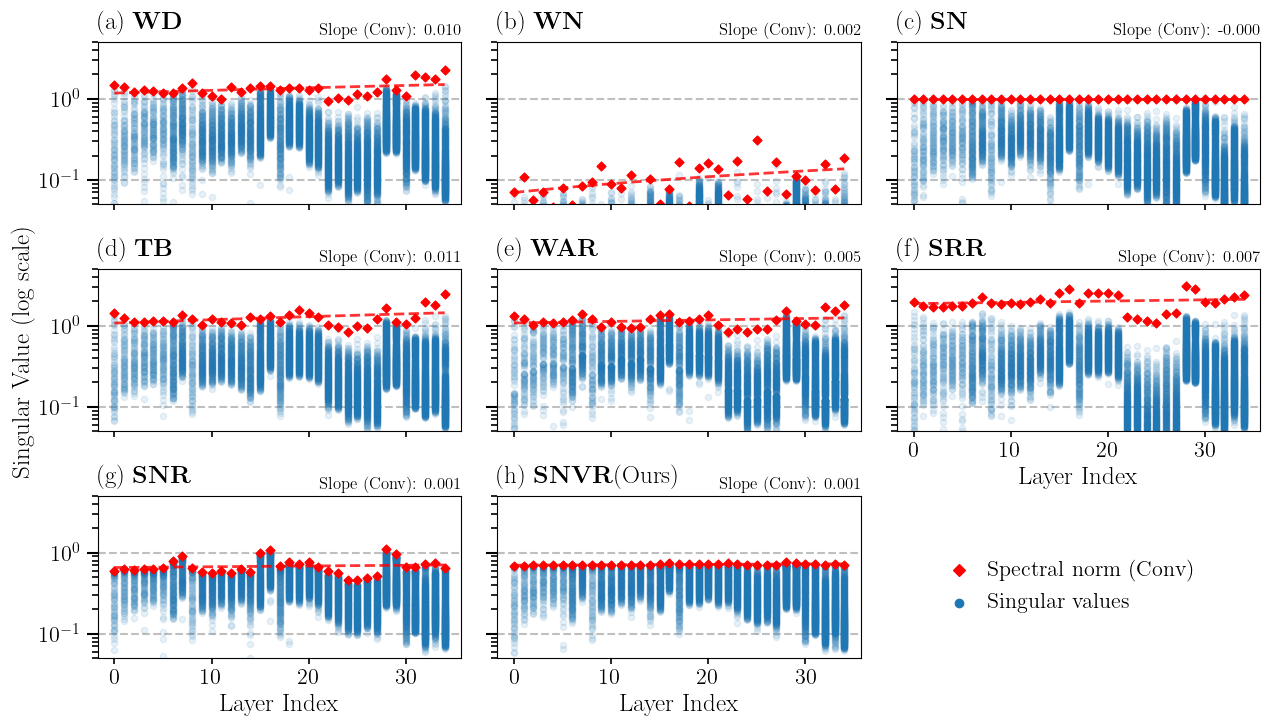

In [ ]:
from torchvision.models import resnet18, resnet34
from models.conv2next import conv2next_tiny
from optimizer.snvr import calc_sn_uv

import torch.nn as nn
import torch

from math import ceil

titles = [r'(a) \textbf{WD}', r'(b) \textbf{WN}', r'(c) \textbf{SN}', r'(d) \textbf{TB}', r'(e) \textbf{WAR}', r'(f) \textbf{SRR}', r'(g) \textbf{SNR}', r'(h) \textbf{SNVR}(Ours)']
methods = ['baseline', 'wn', 'sn', 'tb', 'war', 'srr', 'snr', 'snvr']

fig, axs = plt.subplots(3, 3, figsize=(15, 8))

for i, method in enumerate(methods):
    print(f'=== {method} ===')
    
    ckpt = torch.load(f'./output/resnet34/cifar100/{method}/0/ckpt_best.pt')

    model = resnet34(num_classes=100)
    model.conv1 = nn.Conv2d(3, 64, kernel_size=3, stride=1, padding=1, bias=False)
    model.maxpool = nn.Identity()

    modules = [m for m in model.modules() if isinstance(m, (nn.Conv2d, nn.Linear))]
    modules = modules[1:-1]

    if method == 'wn':
        for m in modules:
            if hasattr(m, 'weight'):
                torch.nn.utils.weight_norm(m, name='weight', dim=0)
    elif method == 'sn':
        for m in modules:
            if hasattr(m, 'weight'):
                torch.nn.utils.spectral_norm(m, name='weight', n_power_iterations=1)
    model.load_state_dict(ckpt['model'], strict=True)

    dummy_input = torch.randn(2, 3, 32, 32)
    model.eval()
    model(dummy_input)


    modules = [m for m in model.modules() if isinstance(m, (nn.Conv2d, nn.Linear))]
    modules = modules[1:-1]

    ax = axs.flatten()[i]

    all_x = []
    all_y = []
    conv_x = []
    conv_y = []
    linear_x = []
    linear_y = []
    for idx, module in enumerate(modules):
        if isinstance(module, nn.Conv2d):
            color = 'red'
            marker = 'D'
            weight = module.weight.data
            weight = weight.view(weight.size(0), -1)
            sn = torch.linalg.svd(weight).S.flatten()
            conv_x.append(idx)
            conv_y.append(sn.max().cpu().numpy())
        elif isinstance(module, nn.Linear):
            color = 'orange'
            marker = 's'
            weight = module.weight.data
            sn = torch.linalg.svd(weight).S.flatten()
            linear_x.append(idx)
            linear_y.append(sn.max().cpu().numpy())
        all_x.append(idx)
        all_y.append(sn.max().cpu().numpy())
        ax.scatter([idx]*len(sn), sn.cpu().numpy(), alpha=0.1, c='C0', s=20, marker='o')
        ax.scatter(idx, sn.max().cpu().numpy(), color=color, s=20, marker=marker)
        idx += 1

    x = np.array(conv_x)
    y = np.array(conv_y)
    z = np.polyfit(x, y, 1)
    p = np.poly1d(z)
    ax.plot(all_x, p(all_x), "--", color='red', alpha=0.8, linewidth=2)
    slope_conv = z[0]
    
    ax.text(1, 1.02, f'Slope (Conv): {slope_conv:.3f}', fontsize=12, ha='right', va='bottom', transform=ax.transAxes)

    ax.set_title(titles[i], fontsize=18, loc='left', pad=10)
    ax.set_ylim(0.05, 5)
    ax.set_yscale('log')
    
    if i in [5, 6, 7]:
        ax.set_xlabel('Layer Index', fontsize=18)
    else:
        ax.set_xticklabels([])

    if i == 3:
        ax.set_ylabel('Singular Value (log scale)', fontsize=18)
    
    if i % 3 != 0:
        ax.set_yticklabels([])

    for y in [0.01, 0.1, 1, 10, 100]:
        ax.axhline(y, linestyle='--', color='gray', alpha=0.5, zorder=-1)
    
    ax.tick_params(labelsize=16, which='major', axis='y', size=8, width=1.5)
    ax.tick_params(labelsize=16, which='minor', axis='y', size=4, width=1.2)
    ax.tick_params(labelsize=16, axis='x', size=4, width=1.2)
    
ax = axs.flatten()[8]
ax.axis('off')

ax = axs.flatten()[7]
ax.scatter([], [], color='red', marker='D', label='Spectral norm (Conv)')
ax.scatter([], [], color='C0', marker='o', label='Singular values')
fig.legend(fontsize=16, loc='right', ncol=1, frameon=False, columnspacing=0.5, handletextpad=0.3, bbox_to_anchor=(0.87, 0.20))

plt.subplots_adjust(wspace=0.1, hspace=0.4)
plt.savefig('figures/visualization_singular_value_resnet34.pdf', bbox_inches='tight', dpi=300)

=== baseline ===
=== wn ===
=== sn ===
=== tb ===
=== war ===
=== srr ===
=== snr_0.01 ===
=== snvr_1.0 ===


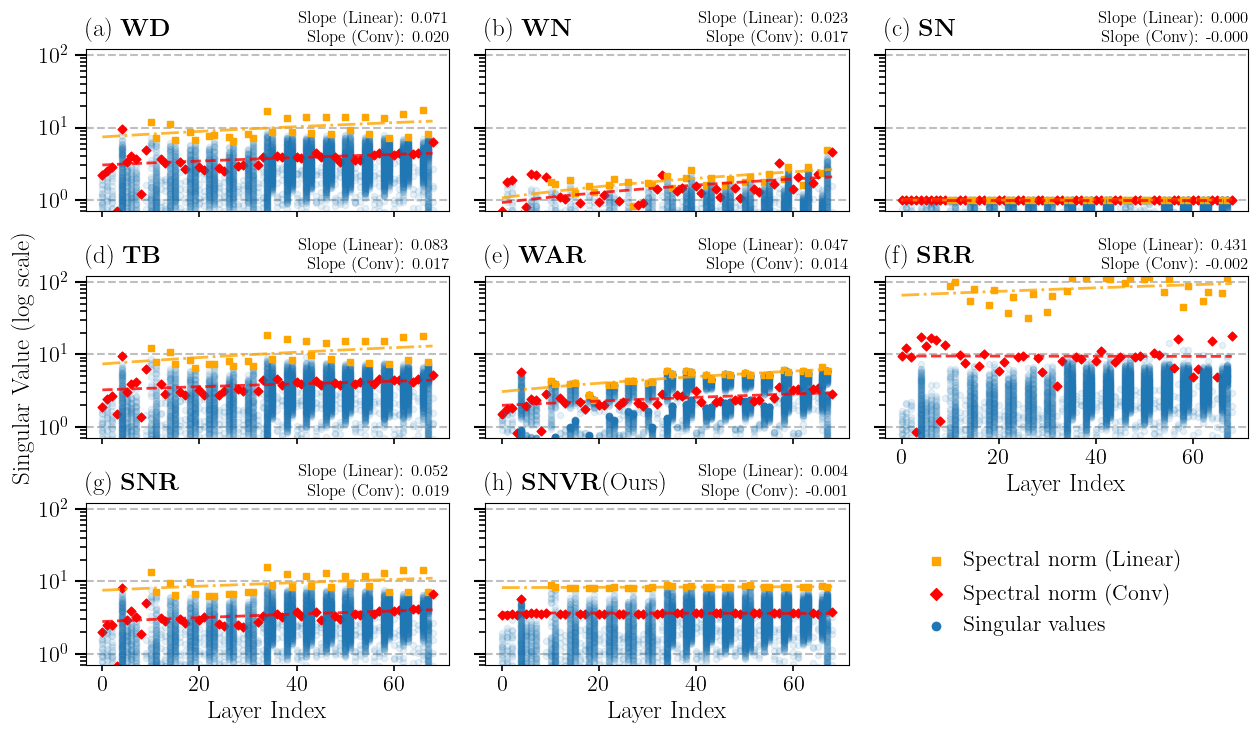

In [ ]:
from torchvision.models import resnet18, resnet34
from models.conv2next import conv2next_tiny
from optimizer.snvr import calc_sn_uv

import torch.nn as nn
import torch

from math import ceil

titles = [r'(a) \textbf{WD}', r'(b) \textbf{WN}', r'(c) \textbf{SN}', r'(d) \textbf{TB}', r'(e) \textbf{WAR}', r'(f) \textbf{SRR}', r'(g) \textbf{SNR}', r'(h) \textbf{SNVR}(Ours)']
methods = ['baseline', 'wn', 'sn', 'tb', 'war', 'srr', 'snr_0.01', 'snvr_1.0']

fig, axs = plt.subplots(3, 3, figsize=(15, 8))

for i, method in enumerate(methods):
    print(f'=== {method} ===')
    
    ckpt = torch.load(f'./output/conv2next-tiny/cifar100/{method}/0/ckpt_best.pt')
    
    model = conv2next_tiny(num_classes=100)

    modules = [m for m in model.modules() if isinstance(m, (nn.Conv2d, nn.Linear))]
    modules = modules[1:-1]

    if method == 'wn':
        for m in modules:
            if hasattr(m, 'weight'):
                torch.nn.utils.weight_norm(m, name='weight', dim=0)
    elif method == 'sn':
        for m in modules:
            if hasattr(m, 'weight'):
                torch.nn.utils.spectral_norm(m, name='weight', n_power_iterations=1)
    model.load_state_dict(ckpt['model'], strict=True)

    dummy_input = torch.randn(2, 3, 32, 32)
    model.eval()
    model(dummy_input)


    modules = [m for m in model.modules() if isinstance(m, (nn.Conv2d, nn.Linear))]
    modules = modules[1:-1]

    ax = axs.flatten()[i]

    all_x = []
    all_y = []
    conv_x = []
    conv_y = []
    linear_x = []
    linear_y = []
    for idx, module in enumerate(modules):
        if isinstance(module, nn.Conv2d):
            color = 'red'
            marker = 'D'
            weight = module.weight.data
            weight = weight.view(weight.size(0), -1)
            sn = torch.linalg.svd(weight).S.flatten()
            conv_x.append(idx)
            conv_y.append(sn.max().cpu().numpy())
        elif isinstance(module, nn.Linear):
            color = 'orange'
            marker = 's'
            weight = module.weight.data
            sn = torch.linalg.svd(weight).S.flatten()
            linear_x.append(idx)
            linear_y.append(sn.max().cpu().numpy())
        all_x.append(idx)
        all_y.append(sn.max().cpu().numpy())
        ax.scatter([idx]*len(sn), sn.cpu().numpy(), alpha=0.1, c='C0', s=20, marker='o')
        ax.scatter(idx, sn.max().cpu().numpy(), color=color, s=20, marker=marker)
        idx += 1

    x = np.array(linear_x)
    y = np.array(linear_y)
    z = np.polyfit(x, y, 1)
    p = np.poly1d(z)
    slope_linear = z[0]
    ax.plot(all_x, p(all_x), "-.", color='orange', alpha=0.8, linewidth=2)

    x = np.array(conv_x)
    y = np.array(conv_y)
    z = np.polyfit(x, y, 1)
    p = np.poly1d(z)
    ax.plot(all_x, p(all_x), "--", color='red', alpha=0.8, linewidth=2)
    slope_conv = z[0]
    
    ax.text(1, 1.14, f'Slope (Linear): {slope_linear:.3f}', fontsize=12, ha='right', va='bottom', transform=ax.transAxes)
    ax.text(1, 1.02, f'Slope (Conv): {slope_conv:.3f}', fontsize=12, ha='right', va='bottom', transform=ax.transAxes)

    ax.set_title(titles[i], fontsize=18, loc='left', pad=10)
    ax.set_ylim(0.7, 120)
    ax.set_yscale('log')
    
    if i in [5, 6, 7]:
        ax.set_xlabel('Layer Index', fontsize=18)
    else:
        ax.set_xticklabels([])

    if i == 3:
        ax.set_ylabel('Singular Value (log scale)', fontsize=18)
    
    if i % 3 != 0:
        ax.set_yticklabels([])

    for y in [0.01, 0.1, 1, 10, 100]:
        ax.axhline(y, linestyle='--', color='gray', alpha=0.5, zorder=-1)
    
    ax.tick_params(labelsize=16, which='major', axis='y', size=8, width=1.5)
    ax.tick_params(labelsize=16, which='minor', axis='y', size=4, width=1.2)
    ax.tick_params(labelsize=16, axis='x', size=4, width=1.2)
    
ax = axs.flatten()[8]
ax.axis('off')

ax = axs.flatten()[7]
ax.scatter([], [], color='orange', marker='s', label='Spectral norm (Linear)')
ax.scatter([], [], color='red', marker='D', label='Spectral norm (Conv)')
ax.scatter([], [], color='C0', marker='o', label='Singular values')
fig.legend(fontsize=16, loc='right', ncol=1, frameon=False, columnspacing=0.5, handletextpad=0.3, bbox_to_anchor=(0.87, 0.20))

plt.subplots_adjust(wspace=0.1, hspace=0.4)
plt.savefig('figures/visualization_singular_value.pdf', bbox_inches='tight', dpi=300)

/home/work/js/anaconda3/envs/snvr/lib/python3.7/site-packages/ipykernel_launcher.py:39: UserWarning: FixedFormatter should only be used together with FixedLocator
/home/work/js/anaconda3/envs/snvr/lib/python3.7/site-packages/ipykernel_launcher.py:39: UserWarning: FixedFormatter should only be used together with FixedLocator
/home/work/js/anaconda3/envs/snvr/lib/python3.7/site-packages/ipykernel_launcher.py:39: UserWarning: FixedFormatter should only be used together with FixedLocator
/home/work/js/anaconda3/envs/snvr/lib/python3.7/site-packages/ipykernel_launcher.py:39: UserWarning: FixedFormatter should only be used together with FixedLocator


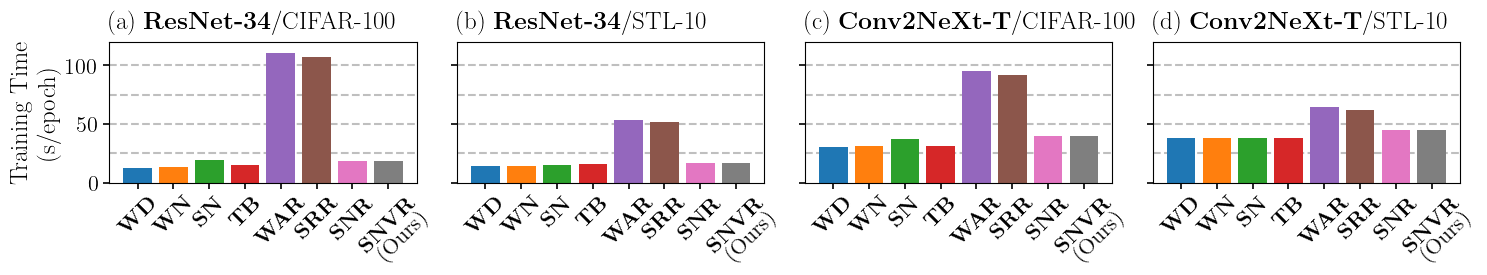

In [ ]:
from itertools import product
from datetime import datetime

titles = [r'(a) \textbf{ResNet-34}/CIFAR-100', r'(b) \textbf{ResNet-34}/STL-10', r'(c) \textbf{Conv2NeXt-T}/CIFAR-100', r'(d) \textbf{Conv2NeXt-T}/STL-10']
method_ticks = [r'\textbf{WD}', r'\textbf{WN}', r'\textbf{SN}', r'\textbf{TB}', r'\textbf{WAR}', r'\textbf{SRR}', r'\textbf{SNR}', r'\textbf{SNVR}']
methods = ['baseline', 'wn', 'sn', 'tb', 'war', 'srr', 'snr', 'snvr']
models = ['resnet34', 'conv2next-tiny']
datasets = ['cifar100', 'stl10']
model_dataset_pairs = list(product(models, datasets))

fig, axs = plt.subplots(1, 4, figsize=(15, 3))

for idx, (model, dataset) in enumerate(model_dataset_pairs):
    ax = axs[idx]

    for method in methods:
        with open(f'output_compute_time/{model}/{dataset}/{method}/0/log_rank0.txt', 'r') as f:
            lines = f.readlines()
            for line in lines:
                if 'INFO Start training' in line:
                    line = line.split(']')[0].split('[')[1]
                    start_time = datetime.strptime(line, '%Y-%m-%d %H:%M:%S')
            end_time = datetime.strptime(lines[-1].split(']')[0].split('[')[1], '%Y-%m-%d %H:%M:%S')
            total_time = (end_time - start_time).total_seconds()
        ax.bar(method, total_time/5)

    ax.set_title(titles[idx], fontsize=18, loc='left', pad=10)

    if idx == 0:
        ax.set_ylabel('Training Time\n(s/epoch)', fontsize=18)
    else:
        ax.set_yticklabels([])
       
    ax.set_ylim(0, 120)
    
    for y in [25, 50, 75, 100]:
        ax.axhline(y, linestyle='--', color='gray', alpha=0.5, zorder=-1)
    
    ax.set_xticklabels(method_ticks, rotation=45, ha='center', fontsize=16)
    ax.tick_params(labelsize=16, which='major', axis='both', size=4, width=1.2)

    ax.text(0.96, -0.16, '(Ours)', fontsize=16, ha='center', va='top', transform=ax.transAxes, rotation=45)
    
plt.tight_layout()
plt.savefig('figures/computation_time.pdf', dpi=300)